# Coocorrência de atividades no mesmo ciclo (número de ciclos)

Mesmo gráfico de `graphic/activities/grafico_coocorrencia_atividades.ipynb`, agora alimentado pelo CSV.
Cada célula é o número de ciclos (estudos) que têm as duas atividades; a diagonal (contornada) é o número de ciclos em que a atividade aparece sozinha. Usa as mesmas combinações do UpSet truncado (≥ 3 ciclos).

Saída: `activity_cooccurrence.pdf` e `coocorrencia_atividades.png`, nesta pasta.

In [1]:
import sys
sys.path.insert(0, ".")
sys.path.insert(0, "../scripts")   # graficos/scripts/paleta.py

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from paleta import TONS, tom, cmap_sequencial

## Dados

Combinações de atividades por estudo, calculadas a partir de `../data/tabela_de_codigos.csv` em `dados_atividades.py`. Nenhum número é digitado à mão.

In [2]:
# Combinações de atividades por estudo, calculadas de ../data/tabela_de_codigos.csv (dados_atividades.py).
# COMBINACOES: estudos por combinação EXATA de atividades, só as com >= MINIMO, em ordem decrescente.
# CICLOS_POR_ATIVIDADE: estudos em que cada atividade aparece, contando só as combinações mostradas.
from dados_atividades import (ATIVIDADES_ARTEFATO, ATIVIDADES_APOIO, ORDEM, COMBINACOES, CICLOS_POR_ATIVIDADE,
                              TOTAL_CICLOS, CICLOS_MOSTRADOS, CICLOS_NAO_MOSTRADOS, COMBINACOES_NAO_MOSTRADAS,
                              COOCORRENCIA)
print(f"{len(COMBINACOES)} combinações mostradas ({CICLOS_MOSTRADOS} de {TOTAL_CICLOS} estudos); "
      f"{COMBINACOES_NAO_MOSTRADAS} não mostradas ({CICLOS_NAO_MOSTRADOS} estudos)")

35 combinações mostradas (398 de 493 estudos); 79 não mostradas (95 estudos)


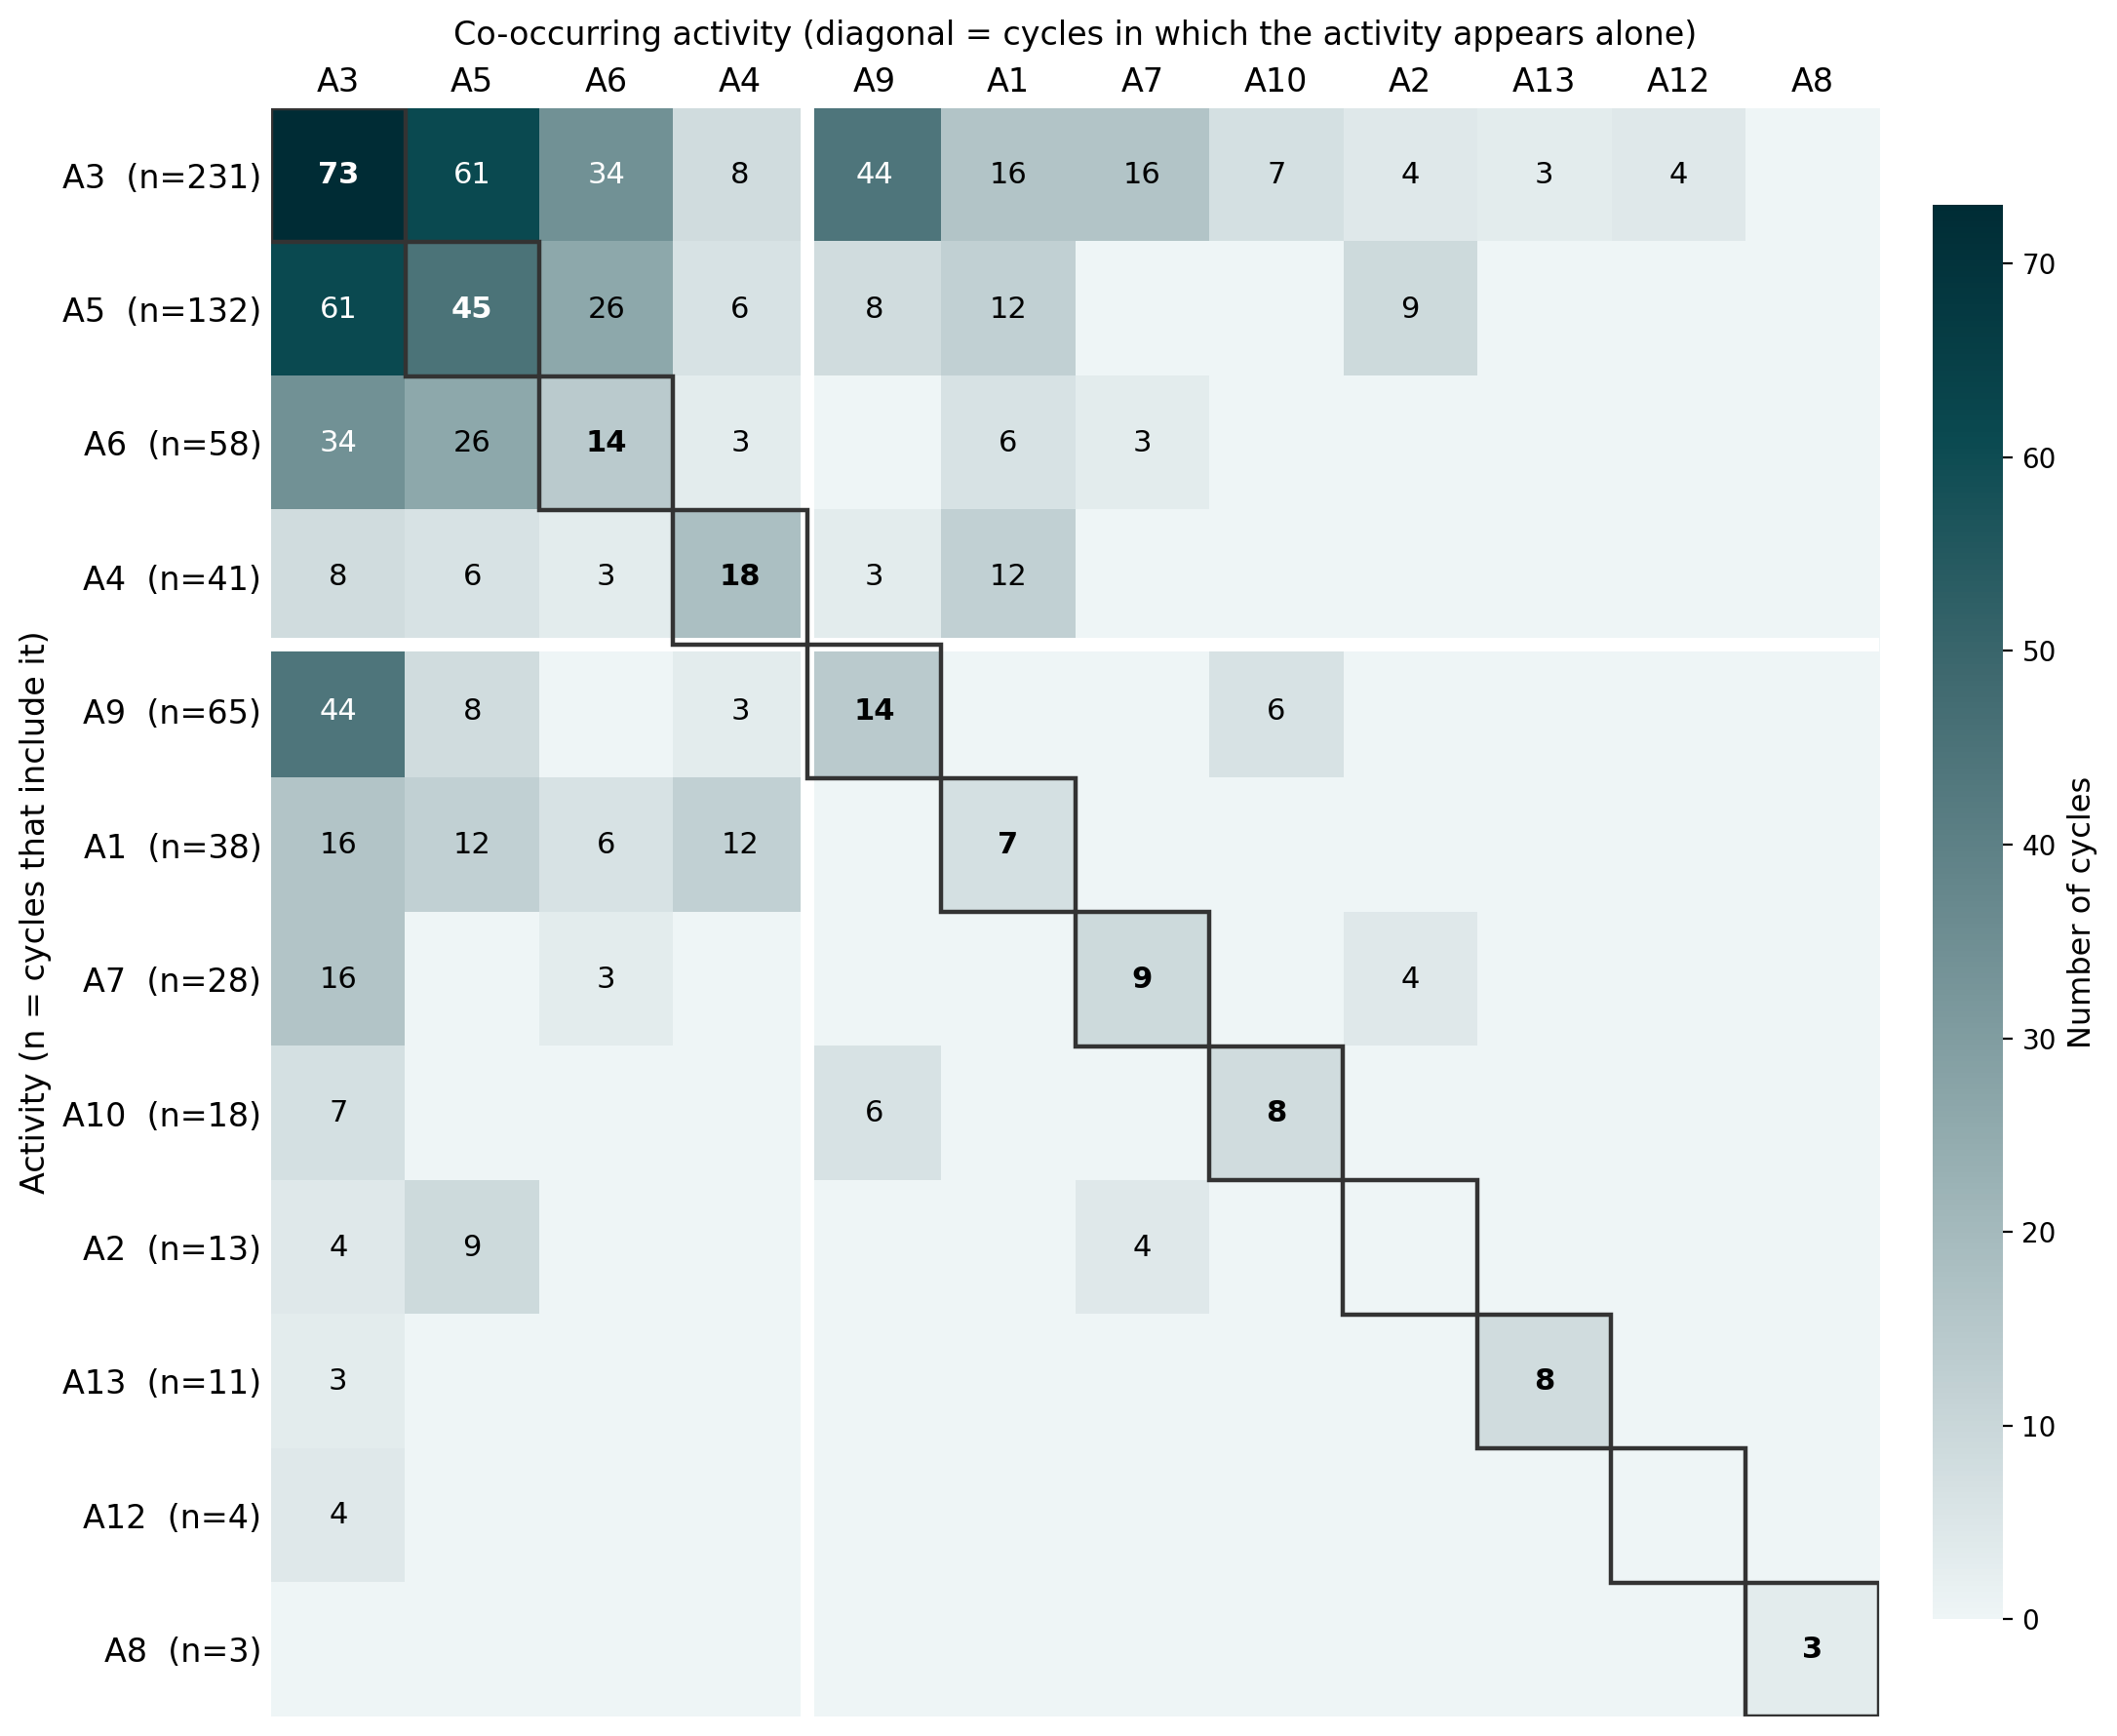

In [3]:
n = len(ORDEM)
n_art = len(ATIVIDADES_ARTEFATO)
pos = {a: i for i, a in enumerate(ORDEM)}

# contagens exatas a partir das combinações do UpSet:
# fora da diagonal = ciclos com as duas atividades; diagonal = ciclos só com a atividade
contagem = np.zeros((n, n), dtype=int)
for combo, ciclos in COMBINACOES:
    if len(combo) == 1:
        a = next(iter(combo))
        contagem[pos[a], pos[a]] += ciclos
    for a in combo:
        for b in combo:
            if a != b:
                contagem[pos[a], pos[b]] += ciclos
assert (contagem == COOCORRENCIA).all(), "contagens não batem com dados_atividades.COOCORRENCIA"
assert (contagem == contagem.T).all()

cmap = cmap_sequencial("cooc", com_branco=False)
cmap.set_bad(tom(0))                      # células vazias (0)
masc = np.ma.masked_where(contagem == 0, contagem)
vmax = contagem.max()

fig, ax = plt.subplots(figsize=(10.5, 9), dpi=200)
im = ax.imshow(masc, cmap=cmap, vmin=0, vmax=vmax, aspect="equal")

for i in range(n):
    for j in range(n):
        v = contagem[i, j]
        if v == 0:
            continue
        r, g, b, _ = cmap(v / vmax)
        cor = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.55 else "black"
        ax.text(j, i, str(v), ha="center", va="center", fontsize=11,
                fontweight="bold" if i == j else "normal", color=cor)

# contorno da diagonal
for i in range(n):
    ax.add_patch(Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False,
                           edgecolor="#333333", linewidth=1.6, zorder=3))
# separação entre atividades que geram artefato e atividades de apoio
ax.axhline(n_art - 0.5, color="white", linewidth=5, zorder=2)
ax.axvline(n_art - 0.5, color="white", linewidth=5, zorder=2)

rotulos = [f"A{a}" for a in ORDEM]
ax.set_xticks(range(n))
ax.set_xticklabels(rotulos, fontsize=12)
ax.xaxis.tick_top()
ax.set_yticks(range(n))
ax.set_yticklabels([f"A{a}  (n={CICLOS_POR_ATIVIDADE[a]})" for a in ORDEM], fontsize=12)
ax.tick_params(length=0)
ax.set_xlabel("Co-occurring activity (diagonal = cycles in which the activity appears alone)",
              fontsize=12, color="black", labelpad=8)
ax.xaxis.set_label_position("top")
ax.set_ylabel("Activity (n = cycles that include it)", fontsize=12, color="black")
for s in ax.spines.values():
    s.set_visible(False)

cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
cbar.set_label("Number of cycles", fontsize=11.5)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.savefig("activity_cooccurrence.pdf", bbox_inches="tight")
plt.savefig("coocorrencia_atividades.png", bbox_inches="tight", dpi=200)
plt.show()